# Generalised Railway Platform Allocation — Methodology Validation Benchmark V9.1

**Purpose:** improve the methodological strength of V9 without increasing the maximum instance size. V9.1 keeps the same synthetic railway generator, six-platform model, one-hot encoding, SA/SQA solvers, train-count range (up to 2,048), exact-search scope, and core output measures. It adds (1) a second, less generator-specialised Greedy baseline, (2) a mathematically justified feasible-upper-bound penalty, (3) a paired conservative-penalty control on preselected sizes, (4) stronger sampler budgets for medium and large instances, and (5) sampler request/response metadata logging.

**Important:** V9 remains the frozen baseline. V9.1 is a new controlled follow-up experiment. Do not overwrite V9 outputs. OpenJij SQA remains a classical simulation, not quantum hardware. All railway schedules and conflicts remain synthetic and station-independent.

## 0. Environment setup
Run this cell only if required packages are missing. OpenJij 0.12.x was used in the preceding experiments.

In [12]:
%pip install -q openjij numpy pandas matplotlib psutil

Note: you may need to restart the kernel to use updated packages.


## 1. Imports and machine information

In [13]:
import sys, platform, time, math, json, itertools, random, importlib.metadata, warnings, os, gc
from pathlib import Path
from typing import Dict, List, Tuple, Optional, Any
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import openjij as oj
except ImportError as exc:
    raise ImportError("OpenJij is required. Install it in this notebook kernel, then restart the kernel.") from exc

try:
    import psutil
    RAM_GB = round(psutil.virtual_memory().total / 1024**3, 2)
except Exception:
    psutil = None
    RAM_GB = None
try:
    OPENJIJ_VERSION = importlib.metadata.version("openjij")
except Exception:
    OPENJIJ_VERSION = getattr(oj, "__version__", "version not exposed")

print("Python:", sys.version.split()[0])
print("OS:", platform.platform())
print("CPU:", platform.processor() or "not exposed")
print("RAM (GB):", RAM_GB)
print("OpenJij:", OPENJIJ_VERSION)

Python: 3.12.12
OS: Windows-11-10.0.26300-SP0
CPU: Intel64 Family 6 Model 143 Stepping 8, GenuineIntel
RAM (GB): 127.65
OpenJij: 0.12.2


## 2. Pre-registered experiment controls

V9.1 preserves the V9 datasets and train-count range. Start with `PILOT` to check runtime and the new penalty comparison; after review, switch to `FULL` for all 78 datasets through 2,048 trains.

The primary model uses an **upper-bound-safe penalty**: `lambda = U + 1`, where `U` is the best cost among independently generated, validated Greedy feasible assignments. The objective is non-negative; every invalid binary state incurs at least one unit-constraint penalty of `lambda`; and a feasible solution with cost `U` is known to exist. Therefore every global QUBO minimizer is feasible. This is an exact-penalty argument, not a claim that the sampler will find the ground state.

To isolate the penalty effect, a paired control reruns a preselected subset with the original V9 penalty `lambda = N + 1`, using the same datasets, read/sweep budgets, repeats, and per-run random seeds as the primary runs. The control sizes are fixed before execution and exported in metadata.

Large-instance sampler budgets are increased from V9. This makes V9.1 more informative, but it also means comparisons to V9 must report the budget change explicitly.

In [14]:
# V9.1 pre-registered settings. Set to FULL only after reviewing the pilot.
STUDY_MODE = "FULL"  # "PILOT" or "FULL"
RUN_EXPERIMENT = True
RUN_SAMPLERS = True
RUN_CONSERVATIVE_PENALTY_CONTROL = True

N_PLATFORMS = 6
LONG_PLATFORM_COUNT = 4
LONG_TRAIN_COACH_THRESHOLD = 24
CLEARANCE_MIN = 5  # Declared modelling assumption, in minutes.
DIFFICULTIES = ["low", "medium", "high"]
GREEDY_RESTARTS = 20
SEED_BASE = 881100  # New namespace; does not reuse V9 sampler seeds.

# Exact search remains a reference only; larger cases are deliberately not submitted.
EXACT_MAX_TRAINS = 32
EXACT_TIME_LIMIT_S = 2.0

# Experimental safety limits. These are not mathematical limits.
MAX_QUBO_VARIABLES = 16000
MAX_QUBO_INTERACTIONS = 500000

# V9 synthetic scenario definitions are intentionally unchanged.
DIFFICULTY_CONFIG = {
    "low":    {"dwell_min": 12, "dwell_max": 20, "delay_max_min": 3,
               "target_utilization": 0.55, "nominal_witness_probability": 0.80},
    "medium": {"dwell_min": 15, "dwell_max": 25, "delay_max_min": 8,
               "target_utilization": 0.70, "nominal_witness_probability": 0.55},
    "high":   {"dwell_min": 18, "dwell_max": 30, "delay_max_min": 15,
               "target_utilization": 0.84, "nominal_witness_probability": 0.30},
}

if STUDY_MODE.upper() == "PILOT":
    TRAIN_COUNTS = [8, 16, 32, 64]
    SEEDS_BY_SIZE = {n: [11, 22] for n in TRAIN_COUNTS}
    PENALTY_CONTROL_SIZES = [16, 64]
    BUDGET_BY_SIZE = {
        "small":  {"repeats": 3, "num_reads": 40, "num_sweeps": 400},
        "medium": {"repeats": 3, "num_reads": 30, "num_sweeps": 300},
        "large":  {"repeats": 2, "num_reads": 16, "num_sweeps": 200},
    }
elif STUDY_MODE.upper() == "FULL":
    TRAIN_COUNTS = [8, 16, 32, 64, 128, 256, 512, 1024, 1536, 2048]
    SEEDS_BY_SIZE = {
        8: [11, 22, 33], 16: [11, 22, 33], 32: [11, 22, 33], 64: [11, 22, 33],
        128: [11, 22, 33], 256: [11, 22, 33], 512: [11, 22], 1024: [11, 22],
        1536: [11, 22], 2048: [11, 22],
    }
    # Paired control at four pre-registered sizes, covering small to largest instances.
    PENALTY_CONTROL_SIZES = [64, 256, 1024, 2048]
    BUDGET_BY_SIZE = {
        "small":  {"repeats": 3, "num_reads": 40, "num_sweeps": 400},
        "medium": {"repeats": 3, "num_reads": 30, "num_sweeps": 300},
        "large":  {"repeats": 2, "num_reads": 16, "num_sweeps": 200},
    }
else:
    raise ValueError("STUDY_MODE must be PILOT or FULL")


def budget_tier(n):
    if n <= 64: return "small"
    if n <= 256: return "medium"
    return "large"

EXPECTED_DATASETS = sum(len(SEEDS_BY_SIZE[n]) for n in TRAIN_COUNTS) * len(DIFFICULTIES)
EXPECTED_MAIN_CALLS = sum(
    len(SEEDS_BY_SIZE[n]) * len(DIFFICULTIES) * 2 * BUDGET_BY_SIZE[budget_tier(n)]["repeats"]
    for n in TRAIN_COUNTS
)
EXPECTED_CONTROL_CALLS = (
    sum(
        len(SEEDS_BY_SIZE[n]) * len(DIFFICULTIES) * 2 * BUDGET_BY_SIZE[budget_tier(n)]["repeats"]
        for n in PENALTY_CONTROL_SIZES if n in SEEDS_BY_SIZE
    ) if RUN_CONSERVATIVE_PENALTY_CONTROL else 0
)
EXPECTED_CALLS = EXPECTED_MAIN_CALLS + EXPECTED_CONTROL_CALLS

print("Study mode:", STUDY_MODE)
print("Train counts:", TRAIN_COUNTS)
print("Expected datasets:", EXPECTED_DATASETS)
print("Primary adaptive-penalty sampler calls:", EXPECTED_MAIN_CALLS)
print("Paired conservative-penalty control calls:", EXPECTED_CONTROL_CALLS)
print("Total planned sampler calls:", EXPECTED_CALLS)
print("Penalty: lambda = best validated Greedy feasible cost + 1")
print("Conservative control sizes:", PENALTY_CONTROL_SIZES)
print("Budgets:", BUDGET_BY_SIZE)
print("Generator and difficulty definitions are unchanged from V9.")
print("Exact-search limit:", EXACT_MAX_TRAINS, "trains /", EXACT_TIME_LIMIT_S, "seconds per dataset")
print("No witness assignment is supplied to either sampler.")

Study mode: FULL
Train counts: [8, 16, 32, 64, 128, 256, 512, 1024, 1536, 2048]
Expected datasets: 78
Primary adaptive-penalty sampler calls: 420
Paired conservative-penalty control calls: 156
Total planned sampler calls: 576
Penalty: lambda = best validated Greedy feasible cost + 1
Conservative control sizes: [64, 256, 1024, 2048]
Budgets: {'small': {'repeats': 3, 'num_reads': 40, 'num_sweeps': 400}, 'medium': {'repeats': 3, 'num_reads': 30, 'num_sweeps': 300}, 'large': {'repeats': 2, 'num_reads': 16, 'num_sweeps': 200}}
Generator and difficulty definitions are unchanged from V9.
Exact-search limit: 32 trains / 2.0 seconds per dataset
No witness assignment is supplied to either sampler.


### V9.1 experimental factors at a glance

| Factor | Primary condition | Paired control |
|---|---|---|
| Penalty | `U + 1` from best validated Greedy upper bound | Original V9 `N + 1` |
| Greedy baselines | Original interval/reservation Greedy plus generic MRV Greedy | Same two heuristics |
| Large budget | 2 repeats × 16 reads × 200 sweeps | Exactly matched on control subset |
| Medium budget | 3 repeats × 30 reads × 300 sweeps | Exactly matched on control subset |
| Sampler seeds | Fixed by dataset/algorithm/repeat | Same seed reused for paired penalty control |

The conservative penalty control is intentionally limited to pre-registered sizes to keep the runtime bounded.

## 3. Synthetic railway instance generator and validation

In [15]:
def generate_instance(n_trains: int, difficulty: str, seed: int,
                      n_platforms: int = N_PLATFORMS,
                      long_platform_count: int = LONG_PLATFORM_COUNT,
                      clearance_min: int = CLEARANCE_MIN) -> pd.DataFrame:
    """Generate an always-feasible interval-allocation instance.

    The hidden witness uses the long-capable platform pool for long trains and the
    short-only platform pool for short trains. Intervals are sequenced independently
    on each witness platform. The full eligibility rules remain unchanged for solvers.
    The witness is exported for audit, but never passed to QUBO or samplers.
    """
    if difficulty not in DIFFICULTY_CONFIG:
        raise ValueError(f"Unknown difficulty: {difficulty}")
    if n_trains < 1 or n_platforms < 2:
        raise ValueError("Need at least one train and two platforms")
    if not 1 <= long_platform_count <= n_platforms:
        raise ValueError("Invalid long-platform count")
    cfg = DIFFICULTY_CONFIG[difficulty]
    rng = np.random.default_rng(seed)
    drafts = []
    witness_loads = {p:0 for p in range(n_platforms)}

    # Determine train attributes and a hidden feasible witness platform.
    for i in range(n_trains):
        coaches = int(rng.integers(10,31))
        is_long = coaches >= LONG_TRAIN_COACH_THRESHOLD
        eligible = list(range(long_platform_count)) if is_long else list(range(n_platforms))
        # The generator witness uses disjoint lane pools: long-capable platforms
        # for long trains, and the remaining short-only platforms for short trains.
        # Solver eligibility is unchanged: short trains may still use every platform.
        witness_pool = list(range(long_platform_count)) if is_long else list(range(long_platform_count,n_platforms))
        if not witness_pool:
            raise ValueError("At least one short-only platform is required for this witness generator")
        min_load = min(witness_loads[p] for p in witness_pool)
        balanced_candidates = [p for p in witness_pool if witness_loads[p] == min_load]
        witness_platform = int(rng.choice(balanced_candidates))
        witness_loads[witness_platform] += 1
        dwell = int(rng.integers(cfg["dwell_min"],cfg["dwell_max"]+1))
        delay = int(rng.integers(0,cfg["delay_max_min"]+1))
        drafts.append({
            "train_index":i,"train_id":f"T{i+1:05d}","coaches":coaches,
            "is_long":bool(is_long),"eligible_platforms":eligible,
            "witness_platform":witness_platform,"dwell_min":dwell,"delay_min":delay,
        })

    # Create a separate chronological lane on each witness platform.
    # Mean idle gap is selected from target utilisation; this keeps load intensity
    # approximately comparable as N grows instead of overloading a fixed time horizon.
    platform_orders = {p:[] for p in range(n_platforms)}
    for item in drafts:
        platform_orders[item["witness_platform"]].append(item["train_index"])
    for p in range(n_platforms):
        rng.shuffle(platform_orders[p])

    times = {}
    mean_dwell = (cfg["dwell_min"] + cfg["dwell_max"]) / 2.0
    target_u = float(cfg["target_utilization"])
    mean_occupied = mean_dwell + int(clearance_min)
    mean_gap = mean_occupied * (1.0-target_u) / target_u
    for p, order in platform_orders.items():
        cursor = 60  # warm-up offset ensures scheduled arrival remains nonnegative after delay
        for i in order:
            gap = max(0,int(round(rng.exponential(mean_gap)))) if mean_gap > 0 else 0
            actual_arrival = cursor + gap
            item = drafts[i]
            actual_departure = actual_arrival + item["dwell_min"]
            scheduled_arrival = actual_arrival - item["delay_min"]
            times[i] = {
                "scheduled_arrival_min":scheduled_arrival,
                "scheduled_departure_min":scheduled_arrival + item["dwell_min"],
                "actual_arrival_min":actual_arrival,
                "actual_departure_min":actual_departure,
            }
            cursor = actual_departure + int(clearance_min)

    rows=[]
    for item in drafts:
        eligible=item["eligible_platforms"]
        witness=item["witness_platform"]
        if rng.random() < float(cfg["nominal_witness_probability"]):
            nominal=witness
        else:
            alternatives=[p for p in eligible if p != witness]
            nominal=int(rng.choice(alternatives)) if alternatives else witness
        rows.append({
            **item,**times[item["train_index"]],
            "nominal_platform":int(nominal),
            "difficulty":difficulty,"seed":int(seed),
            "target_utilization":target_u,
            "nominal_witness_probability":float(cfg["nominal_witness_probability"]),
        })
    return pd.DataFrame(rows)


def interval_conflicts(df: pd.DataFrame, clearance_min: int = CLEARANCE_MIN) -> List[Tuple[int,int]]:
    edges=[]
    n=len(df)
    starts=df["actual_arrival_min"].astype(int).to_numpy()
    ends=(df["actual_departure_min"].astype(int)+int(clearance_min)).to_numpy()
    for i in range(n):
        overlap=(starts[i] < ends[i+1:]) & (starts[i+1:] < ends[i])
        edges.extend((i,i+1+int(offset)) for offset in np.flatnonzero(overlap))
    return edges


def max_interval_concurrency(df: pd.DataFrame, clearance_min: int = CLEARANCE_MIN,
                             long_only: bool = False) -> int:
    subset=df[df.is_long] if long_only else df
    events=[]
    for row in subset.itertuples():
        events.append((int(row.actual_arrival_min),1))
        events.append((int(row.actual_departure_min)+int(clearance_min),-1))
    # End events before start events at equal time: intervals are half-open.
    events.sort(key=lambda x:(x[0],x[1]))
    active=peak=0
    for _,delta in events:
        active+=delta
        peak=max(peak,active)
    return int(peak)


def assignment_cost(assignment: Dict[int,int], df: pd.DataFrame) -> int:
    return int(sum(int(assignment[i]) != int(df.iloc[i].nominal_platform) for i in range(len(df))))


def validate_assignment(assignment: Optional[Dict[int,int]], df: pd.DataFrame,
                        conflicts: List[Tuple[int,int]]) -> Tuple[bool,List[str]]:
    if assignment is None or set(assignment) != set(range(len(df))):
        return False,["missing_train_assignment"]
    violations=[]
    for i,p in assignment.items():
        if int(p) not in [int(x) for x in df.iloc[i].eligible_platforms]:
            violations.append(f"ineligible_platform_train_{i}")
    for i,j in conflicts:
        if assignment.get(i)==assignment.get(j):
            violations.append(f"overlap_conflict_{i}_{j}")
    return len(violations)==0,violations


def conflict_density(n_trains: int, conflicts: List[Tuple[int,int]]) -> float:
    possible=n_trains*(n_trains-1)/2
    return len(conflicts)/possible if possible else 0.0

print("Capacity-aware synthetic generator and validators defined.")

Capacity-aware synthetic generator and validators defined.


## 4. Greedy baseline and bounded exact reference

In [16]:
def greedy_assignment(df: pd.DataFrame, conflicts: List[Tuple[int,int]],
                      seed: int = 0, restarts: int = GREEDY_RESTARTS) -> Optional[Dict[int,int]]:
    """Time-ordered interval greedy with a least-flexible-platform reservation rule.

    Long trains use the long-capable pool. Short trains prefer the short-only pool;
    that pool is sufficient because the generator's hidden witness schedules short
    trains on those lanes. The method does not read or use witness_platform.
    Random tie-breaking yields multiple feasible assignments; best cost is retained.
    """
    n=len(df)
    master_rng=np.random.default_rng(seed)
    best=None; best_cost=float("inf")
    short_only_platforms=list(range(LONG_PLATFORM_COUNT,N_PLATFORMS))
    for _ in range(max(1,int(restarts))):
        rng=np.random.default_rng(int(master_rng.integers(0,2**31-1)))
        order=sorted(
            range(n),
            key=lambda i:(int(df.iloc[i].actual_arrival_min),
                          not bool(df.iloc[i].is_long),
                          float(rng.random()),i)
        )
        available_at={p:-10**18 for p in range(N_PLATFORMS)}
        platform_load={p:0 for p in range(N_PLATFORMS)}
        assigned={}
        for i in order:
            eligible=[int(p) for p in df.iloc[i].eligible_platforms]
            start=int(df.iloc[i].actual_arrival_min)
            available=[p for p in eligible if available_at[p] <= start]
            if not bool(df.iloc[i].is_long):
                # Reserve long-capable platforms for long trains whenever a short-only
                # platform can serve the current short train.
                short_available=[p for p in available if p in short_only_platforms]
                if short_available:
                    available=short_available
            if not available:
                break
            nominal=int(df.iloc[i].nominal_platform)
            available.sort(key=lambda p:(p!=nominal,platform_load[p],float(rng.random())))
            p=available[0]
            assigned[i]=p
            available_at[p]=int(df.iloc[i].actual_departure_min)+CLEARANCE_MIN
            platform_load[p]+=1
        if len(assigned)==n:
            valid,_=validate_assignment(assigned,df,conflicts)
            if valid:
                cost=assignment_cost(assigned,df)
                if cost<best_cost:
                    best,best_cost=assigned.copy(),cost
                if best_cost==0:
                    break
    return best

print("Interval-first-fit Greedy baseline defined.")


def exact_branch_and_bound(df: pd.DataFrame, conflicts: List[Tuple[int,int]],
                           incumbent: Optional[Dict[int,int]] = None,
                           time_limit_s: float = EXACT_TIME_LIMIT_S) -> Dict[str,Any]:
    """Bounded exact search; timeout is never labelled optimal or infeasible."""
    n=len(df)
    neighbours=[set() for _ in range(n)]
    for i,j in conflicts:
        neighbours[i].add(j); neighbours[j].add(i)
    best_assignment=None; best_cost=float("inf")
    if incumbent is not None:
        ok,_=validate_assignment(incumbent,df,conflicts)
        if ok:
            best_assignment=dict(incumbent)
            best_cost=assignment_cost(best_assignment,df)
    start=time.perf_counter(); nodes=0; timed_out=False

    def recurse(assigned: Dict[int,int], current_cost: int):
        nonlocal best_assignment,best_cost,nodes,timed_out
        nodes+=1
        if time.perf_counter()-start >= time_limit_s:
            timed_out=True
            return
        if len(assigned)==n:
            if current_cost<best_cost:
                best_cost=current_cost; best_assignment=dict(assigned)
            return
        domains={}
        for i in range(n):
            if i in assigned: continue
            used={assigned[j] for j in neighbours[i] if j in assigned}
            domains[i]=[int(p) for p in df.iloc[i].eligible_platforms if int(p) not in used]
            if not domains[i]: return
        lower_bound=current_cost
        for i,options in domains.items():
            if int(df.iloc[i].nominal_platform) not in options:
                lower_bound+=1
        if lower_bound>=best_cost: return
        i=min(domains,key=lambda k:(len(domains[k]),-len(neighbours[k]),k))
        nominal=int(df.iloc[i].nominal_platform)
        for p in sorted(domains[i],key=lambda p:(p!=nominal,p)):
            new_cost=current_cost+int(p!=nominal)
            if new_cost>=best_cost: continue
            assigned[i]=p
            recurse(assigned,new_cost)
            del assigned[i]
            if timed_out: return

    recurse({},0)
    elapsed=time.perf_counter()-start
    if timed_out: status="TIMEOUT"
    elif best_assignment is None: status="INFEASIBLE"
    else: status="OPTIMAL"
    return {"status":status,"assignment":best_assignment,
            "cost":best_cost if best_assignment is not None else None,
            "runtime_s":elapsed,"nodes":nodes}

print("Exact branch-and-bound reference solver defined.")


def greedy_assignment_mrv(df: pd.DataFrame, conflicts: List[Tuple[int,int]],
                          seed: int = 0, restarts: int = GREEDY_RESTARTS) -> Optional[Dict[int,int]]:
    """Generic most-constrained-first Greedy baseline.

    Unlike the V9 interval Greedy, this method does not reserve the short-only
    platform pool or use the generator's witness lane structure. It uses only
    public eligibility, temporal conflict edges, nominal assignments, and train
    intervals. It orders trains by domain size, then conflict degree, then arrival.
    Randomized tie-breaking across restarts reduces dependence on one ordering.
    """
    n = len(df)
    neighbours = [set() for _ in range(n)]
    for i, j in conflicts:
        neighbours[i].add(j)
        neighbours[j].add(i)
    master_rng = np.random.default_rng(seed)
    best_assignment = None
    best_cost = float("inf")
    for _ in range(max(1, int(restarts))):
        rng = np.random.default_rng(int(master_rng.integers(0, 2**31 - 1)))
        tie = rng.random(n)
        order = sorted(
            range(n),
            key=lambda i: (
                len(df.iloc[i].eligible_platforms),
                -len(neighbours[i]),
                int(df.iloc[i].actual_arrival_min),
                -(int(df.iloc[i].actual_departure_min) - int(df.iloc[i].actual_arrival_min)),
                tie[i], i,
            ),
        )
        assigned = {}
        platform_load = {p: 0 for p in range(N_PLATFORMS)}
        for i in order:
            forbidden = {assigned[j] for j in neighbours[i] if j in assigned}
            eligible = [int(p) for p in df.iloc[i].eligible_platforms]
            available = [p for p in eligible if p not in forbidden]
            if not available:
                break
            nominal = int(df.iloc[i].nominal_platform)
            jitter = {p: float(rng.random()) for p in available}
            available.sort(key=lambda p: (p != nominal, platform_load[p], jitter[p], p))
            chosen = available[0]
            assigned[i] = chosen
            platform_load[chosen] += 1
        if len(assigned) == n:
            valid, _ = validate_assignment(assigned, df, conflicts)
            if valid:
                cost = assignment_cost(assigned, df)
                if cost < best_cost:
                    best_assignment, best_cost = assigned.copy(), cost
                if best_cost == 0:
                    break
    return best_assignment

print("Second baseline defined: generic most-constrained-first Greedy (no witness-pool reservation).")


Interval-first-fit Greedy baseline defined.
Exact branch-and-bound reference solver defined.
Second baseline defined: generic most-constrained-first Greedy (no witness-pool reservation).


## 5. Scalable one-hot QUBO construction

The one-hot QUBO uses the same objective and constraints as V9:

\[
E(x)=\sum_{i,p\ne p_i^0}x_{ip}
+\lambda\sum_i\left(\sum_{p\in P_i}x_{ip}-1\right)^2
+\lambda\sum_{(i,j)\in C}\sum_{p\in P_i\cap P_j}x_{ip}x_{jp}.
\]

V9 used `lambda = N + 1`. V9.1's primary model instead uses `lambda = U + 1`, where `U` is the best cost among two independently implemented, validated Greedy assignments (or the validated generator witness only as a disclosed fallback if both heuristics fail).

**Why is this safe?** The reassignment objective is non-negative. Any invalid binary state violates at least one assignment or conflict constraint and therefore incurs a penalty of at least `lambda`. A validated feasible assignment with cost `U` exists. Since `lambda > U`, every invalid state has energy greater than that known feasible state; therefore no global QUBO minimizer can be invalid. This is a ground-state guarantee, not a guarantee that SA/SQA samples a ground state.

A paired control on preselected train counts uses the original V9 `lambda = N + 1`, with identical data, solver seeds, reads, sweeps, and repeats. This isolates the penalty-strength effect on the selected subset.

In [17]:
def add_qubo_term(Q, a, b, value):
    key = (a, b) if a <= b else (b, a)
    Q[key] = Q.get(key, 0.0) + float(value)
    if abs(Q[key]) < 1e-12:
        del Q[key]


def estimate_one_hot_size(df, conflicts):
    variables = sum(len(row.eligible_platforms) for row in df.itertuples())
    assignment_interactions = sum(
        len(row.eligible_platforms) * (len(row.eligible_platforms) - 1) // 2
        for row in df.itertuples()
    )
    conflict_interactions = 0
    for i, j in conflicts:
        common = set(map(int, df.iloc[i].eligible_platforms)).intersection(map(int, df.iloc[j].eligible_platforms))
        conflict_interactions += len(common)
    return {
        "estimated_variables": int(variables),
        "estimated_assignment_interactions": int(assignment_interactions),
        "estimated_conflict_interactions": int(conflict_interactions),
        "estimated_quadratic_interactions": int(assignment_interactions + conflict_interactions),
    }


def build_one_hot(df, conflicts, n_platforms=N_PLATFORMS, penalty_value=None):
    """Build one-hot QUBO with explicit penalty.

    penalty_value=None retains the original conservative V9 choice N+1.
    V9.1 supplies an independently verified feasible upper bound U and uses U+1.
    """
    n = len(df)
    lam = float(n + 1) if penalty_value is None else float(penalty_value)
    if not np.isfinite(lam) or lam <= 0:
        raise ValueError("Penalty must be a positive finite number")
    Q = {}
    offset = 0.0
    y = {}
    variables = []
    for i in range(n):
        eligible = [int(p) for p in df.iloc[i].eligible_platforms]
        names = []
        for p in eligible:
            name = f"oh_{i}_{p}"
            y[(i,p)] = name
            variables.append(name)
            names.append(name)
            if p != int(df.iloc[i].nominal_platform):
                add_qubo_term(Q, name, name, 1.0)
        # lambda * (sum(x)-1)^2 = lambda - lambda*sum(x) + 2lambda*sum(x_i*x_j)
        offset += lam
        for name in names:
            add_qubo_term(Q, name, name, -lam)
        for a, b in itertools.combinations(names, 2):
            add_qubo_term(Q, a, b, 2.0 * lam)
    for i, j in conflicts:
        common = set(map(int, df.iloc[i].eligible_platforms)).intersection(
            set(map(int, df.iloc[j].eligible_platforms))
        )
        for p in common:
            add_qubo_term(Q, y[(i,p)], y[(j,p)], lam)
    return {
        "encoding": "one_hot", "Q": Q, "offset": float(offset),
        "variables": variables, "y": y,
        "lambda_assign": lam, "lambda_conflict": lam,
        "penalties": {"assignment": lam, "conflict": lam},
    }


def qubo_metrics(Q, variables, offset):
    nvar = len(variables)
    interactions = sum(1 for a,b in Q if a != b)
    coeffs = [abs(v) for v in Q.values() if abs(v) > 1e-12]
    possible = nvar * (nvar - 1) / 2
    return {
        "n_variables":nvar,
        "n_linear_terms":sum(1 for a,b in Q if a == b),
        "n_quadratic_interactions":interactions,
        "interaction_density":interactions / possible if possible else 0.0,
        "max_abs_coefficient":max(coeffs) if coeffs else 0.0,
        "min_abs_nonzero_coefficient":min(coeffs) if coeffs else 0.0,
        "offset":float(offset),
    }


def evaluate_qubo(Q, offset, sample):
    total = float(offset)
    for (a,b), coefficient in Q.items():
        total += float(coefficient) * int(sample.get(a,0)) * int(sample.get(b,0))
    return float(total)


def direct_one_hot_energy(sample, df, conflicts, lam):
    total = 0.0
    for i in range(len(df)):
        selected = [int(sample.get(f"oh_{i}_{p}",0)) for p in df.iloc[i].eligible_platforms]
        total += sum(
            int(int(p) != int(df.iloc[i].nominal_platform)) * int(sample.get(f"oh_{i}_{p}",0))
            for p in df.iloc[i].eligible_platforms
        )
        total += lam * (sum(selected) - 1) ** 2
    for i,j in conflicts:
        common = set(map(int, df.iloc[i].eligible_platforms)).intersection(map(int, df.iloc[j].eligible_platforms))
        total += lam * sum(int(sample.get(f"oh_{i}_{p}",0)) * int(sample.get(f"oh_{j}_{p}",0)) for p in common)
    return float(total)

print("Direct one-hot QUBO builder and size estimator defined.")

Direct one-hot QUBO builder and size estimator defined.


## 6. Raw sample decoding and exact QUBO identity tests

In [18]:
def encode_assignment(assignment, df, model):
    sample = {v: 0 for v in model["variables"]}
    for i, p in assignment.items():
        sample[model["y"][(int(i), int(p))]] = 1
    return sample


def decode_raw_sample(sample, df, conflicts, model):
    assignment = {}
    for i in range(len(df)):
        eligible = [int(p) for p in df.iloc[i].eligible_platforms]
        selected = [p for p in eligible if int(sample.get(model["y"][(i,p)], 0)) == 1]
        if len(selected) != 1:
            return False, None, "one_hot_cardinality"
        assignment[i] = selected[0]
    valid, violations = validate_assignment(assignment, df, conflicts)
    if not valid:
        return False, None, ";".join(violations[:5])
    return True, assignment, ""


def run_one_hot_identity_check(df, conflicts, tests=30, seed=123, penalty_value=None):
    model = build_one_hot(df, conflicts, N_PLATFORMS, penalty_value=penalty_value)
    rng = np.random.default_rng(seed)
    max_error = 0.0
    for _ in range(tests):
        sample = {v: int(rng.integers(0, 2)) for v in model["variables"]}
        q_energy = evaluate_qubo(model["Q"], model["offset"], sample)
        direct = direct_one_hot_energy(sample, df, conflicts, model["lambda_conflict"])
        max_error = max(max_error, abs(q_energy - direct))
    return {"tests": tests, "max_abs_energy_error": max_error,
            "passed": max_error < 1e-8, "penalty_value": model["lambda_conflict"]}


def exhaustive_tiny_one_hot_test():
    """Exhaustively verify the upper-bound penalty theorem on a tiny instance."""
    tiny = pd.DataFrame([
        {"train_index": 0, "train_id": "A", "nominal_platform": 0, "eligible_platforms": [0, 1]},
        {"train_index": 1, "train_id": "B", "nominal_platform": 0, "eligible_platforms": [0, 1]},
    ])
    edges = [(0, 1)]
    feasible_incumbent = {0: 0, 1: 1}
    upper_bound = assignment_cost(feasible_incumbent, tiny)
    adaptive_lambda = upper_bound + 1
    checks = []
    categorical_costs = []
    for a in range(2):
        for b in range(2):
            assignment = {0: a, 1: b}
            valid, _ = validate_assignment(assignment, tiny, edges)
            if valid:
                categorical_costs.append(assignment_cost(assignment, tiny))
    optimum = min(categorical_costs)
    for lam in [adaptive_lambda, len(tiny) + 1]:
        model = build_one_hot(tiny, edges, 2, penalty_value=lam)
        best_energy = float("inf")
        best_samples = []
        for bits in range(1 << len(model["variables"])):
            sample = {name: (bits >> k) & 1 for k, name in enumerate(model["variables"])}
            energy = evaluate_qubo(model["Q"], model["offset"], sample)
            if energy < best_energy - 1e-12:
                best_energy, best_samples = energy, [sample]
            elif abs(energy - best_energy) < 1e-12:
                best_samples.append(sample)
        all_ground_states_valid = all(decode_raw_sample(s, tiny, edges, model)[0] for s in best_samples)
        checks.append({"penalty": lam, "ground_energy": best_energy,
                       "all_ground_states_valid": all_ground_states_valid,
                       "matches_categorical_optimum": abs(best_energy - optimum) < 1e-8})
    passed = all(x["all_ground_states_valid"] and x["matches_categorical_optimum"] for x in checks)
    return {"variables": 4, "enumerated_bitstrings": 16, "upper_bound": upper_bound,
            "adaptive_penalty": adaptive_lambda, "categorical_optimum": optimum,
            "checks": checks, "passed": passed}

_preview_df = generate_instance(8, "medium", 991)
_preview_edges = interval_conflicts(_preview_df)
_preview_witness = {int(row.train_index): int(row.witness_platform) for row in _preview_df.itertuples()}
_preview_valid, _ = validate_assignment(_preview_witness, _preview_df, _preview_edges)
if not _preview_valid:
    raise AssertionError("Preview witness invalid")
_preview_upper_bound = assignment_cost(_preview_witness, _preview_df)
_preview_adaptive_penalty = _preview_upper_bound + 1
_preview_check = run_one_hot_identity_check(
    _preview_df, _preview_edges, tests=50, seed=1901,
    penalty_value=_preview_adaptive_penalty
)
_tiny_check = exhaustive_tiny_one_hot_test()
print("Adaptive-penalty random-bitstring identity check:", _preview_check)
print("Exhaustive tiny penalty-bound check:", _tiny_check)
if not _preview_check["passed"] or not _tiny_check["passed"]:
    raise AssertionError("One-hot QUBO identity/penalty validation failed.")

Adaptive-penalty random-bitstring identity check: {'tests': 50, 'max_abs_energy_error': 0.0, 'passed': True, 'penalty_value': 5.0}
Exhaustive tiny penalty-bound check: {'variables': 4, 'enumerated_bitstrings': 16, 'upper_bound': 1, 'adaptive_penalty': 2, 'categorical_optimum': 1, 'checks': [{'penalty': 2, 'ground_energy': 1.0, 'all_ground_states_valid': True, 'matches_categorical_optimum': True}, {'penalty': 3, 'ground_energy': 1.0, 'all_ground_states_valid': True, 'matches_categorical_optimum': True}], 'passed': True}


## 7. OpenJij wrapper and runtime metrics

In [19]:
def normalize_qubo(Q, offset):
    max_abs = max([abs(v) for v in Q.values()] or [1.0])
    scale = 1.0 / max_abs if max_abs > 0 else 1.0
    return {k: v * scale for k, v in Q.items()}, float(offset) * scale, scale


def _json_safe(value):
    try:
        return json.dumps(value, sort_keys=True, default=lambda obj: repr(obj))
    except Exception:
        return json.dumps({"unserializable_repr": repr(value)})


def run_openjij(model, df, conflicts, algorithm, num_reads, num_sweeps, seed):
    algorithm = algorithm.upper()
    if algorithm == "SA":
        sampler = oj.SASampler()
    elif algorithm == "SQA":
        sampler = oj.SQASampler()
    else:
        raise ValueError(f"Unknown algorithm: {algorithm}")
    Q_scaled, offset_scaled, scale = normalize_qubo(model["Q"], model["offset"])
    # These are the complete explicit call arguments. OpenJij beta range/schedule
    # defaults are not overridden; response.info is separately retained per run.
    sample_kwargs = {"num_reads": int(num_reads), "num_sweeps": int(num_sweeps), "seed": int(seed)}
    sampler_class = f"{sampler.__class__.__module__}.{sampler.__class__.__name__}"
    memory_before_mb = np.nan
    psutil_module = globals().get("psutil")
    if psutil_module is not None:
        try:
            memory_before_mb = psutil_module.Process(os.getpid()).memory_info().rss / (1024 ** 2)
        except Exception:
            memory_before_mb = np.nan
    start = time.perf_counter()
    response = sampler.sample_qubo(Q_scaled, **sample_kwargs)
    runtime = time.perf_counter() - start
    memory_after_mb = np.nan
    if psutil_module is not None:
        try:
            memory_after_mb = psutil_module.Process(os.getpid()).memory_info().rss / (1024 ** 2)
        except Exception:
            memory_after_mb = np.nan
    variables = list(response.variables)
    total_reads = valid_reads = 0
    best_cost = None
    best_assignment = None
    valid_cost_sum = 0.0
    invalid_reasons = {}
    for sample_arr, energy, occurrence in response.record:
        sample = dict(zip(variables, [int(v) for v in sample_arr]))
        occ = int(occurrence)
        total_reads += occ
        valid, assignment, reason = decode_raw_sample(sample, df, conflicts, model)
        if valid:
            cost = assignment_cost(assignment, df)
            valid_reads += occ
            valid_cost_sum += cost * occ
            if best_cost is None or cost < best_cost:
                best_cost, best_assignment = cost, assignment
        else:
            invalid_reasons[reason] = invalid_reasons.get(reason, 0) + occ
    response_info = getattr(response, "info", {})
    schedule_info = response_info.get("schedule", {}) if isinstance(response_info, dict) else {}
    return {
        "runtime_s": runtime, "total_reads": total_reads, "valid_reads": valid_reads,
        "raw_feasibility_pct": 100 * valid_reads / total_reads if total_reads else 0.0,
        "best_valid_cost": best_cost,
        "mean_valid_cost": valid_cost_sum / valid_reads if valid_reads else np.nan,
        "best_valid_assignment": best_assignment,
        "invalid_reasons_json": json.dumps(invalid_reasons, sort_keys=True),
        "normalization_scale": scale,
        "sampler_class": sampler_class,
        "sample_kwargs_json": _json_safe(sample_kwargs),
        "response_info_json": _json_safe(response_info),
        "annealing_schedule_json": _json_safe(schedule_info),
        "memory_before_rss_mb": memory_before_mb,
        "memory_after_rss_mb": memory_after_mb,
        "memory_delta_rss_mb": (memory_after_mb - memory_before_mb
                                 if pd.notna(memory_before_mb) and pd.notna(memory_after_mb) else np.nan),
        "schedule_note": "OpenJij defaults used unless API defaults are changed; actual response.info['schedule'] is exported when available.",
    }

print("OpenJij wrapper defined. Explicit call arguments and response.info will be exported.")
print("SQA remains a classical simulation, not a quantum hardware execution.")

OpenJij wrapper defined. Explicit call arguments and response.info will be exported.
SQA remains a classical simulation, not a quantum hardware execution.


## 8. Benchmark execution

In [20]:
def make_dataset_id(n, difficulty, seed):
    return f"N{n}_{difficulty.upper()}_S{seed}"


def run_study():
    dataset_rows = []
    train_rows = []
    edge_rows = []
    model_rows = []
    run_rows = []
    dataset_cache = {}

    for n in TRAIN_COUNTS:
        tier = budget_tier(n)
        budget = BUDGET_BY_SIZE[tier]
        for difficulty in DIFFICULTIES:
            for data_seed in SEEDS_BY_SIZE[n]:
                dataset_id = make_dataset_id(n, difficulty, data_seed)
                derived_seed = int(data_seed + n * 1009 + DIFFICULTIES.index(difficulty) * 100003)
                df = generate_instance(n, difficulty, derived_seed)
                conflicts = interval_conflicts(df, CLEARANCE_MIN)

                # Greedy A: original V9 time-ordered interval-first-fit with reservation.
                greedy_a_start = time.perf_counter()
                greedy_a = greedy_assignment(df, conflicts, seed=derived_seed + 5, restarts=GREEDY_RESTARTS)
                greedy_a_runtime = time.perf_counter() - greedy_a_start

                # Greedy B: generic MRV ordering; no witness-pool reservation.
                greedy_b_start = time.perf_counter()
                greedy_b = greedy_assignment_mrv(df, conflicts, seed=derived_seed + 105, restarts=GREEDY_RESTARTS)
                greedy_b_runtime = time.perf_counter() - greedy_b_start

                witness = {int(row.train_index): int(row.witness_platform) for row in df.itertuples()}
                witness_ok, witness_violations = validate_assignment(witness, df, conflicts)
                if not witness_ok:
                    raise AssertionError(f"Generator witness invalid for {dataset_id}: {witness_violations[:5]}")
                witness_cost = assignment_cost(witness, df)
                greedy_a_ok = greedy_a is not None
                greedy_b_ok = greedy_b is not None
                greedy_a_cost = assignment_cost(greedy_a, df) if greedy_a_ok else np.nan
                greedy_b_cost = assignment_cost(greedy_b, df) if greedy_b_ok else np.nan

                feasible_heuristics = []
                if greedy_a_ok:
                    feasible_heuristics.append((int(greedy_a_cost), "Greedy_Interval_Reserved", greedy_a))
                if greedy_b_ok:
                    feasible_heuristics.append((int(greedy_b_cost), "Greedy_MRV_Generic", greedy_b))
                if feasible_heuristics:
                    best_ub, best_greedy_name, best_greedy_assignment = min(feasible_heuristics, key=lambda x: (x[0], x[1]))
                    penalty_source = "best_validated_greedy"
                else:
                    # Explicit fallback only: the generator certificate is validated,
                    # but it is not passed to either sampler as a warm start.
                    best_ub, best_greedy_name, best_greedy_assignment = witness_cost, "Generator_Witness_Fallback", witness
                    penalty_source = "generator_witness_fallback"
                adaptive_lambda = int(best_ub) + 1
                conservative_lambda = int(n) + 1

                # Exact reference gets the best feasible incumbent from both Greedies and witness.
                incumbent_candidates = [(witness_cost, "generator_witness", witness)]
                if greedy_a_ok:
                    incumbent_candidates.append((int(greedy_a_cost), "greedy_interval_reserved", greedy_a))
                if greedy_b_ok:
                    incumbent_candidates.append((int(greedy_b_cost), "greedy_mrv_generic", greedy_b))
                exact_incumbent_cost, exact_incumbent_source, exact_incumbent = min(
                    incumbent_candidates, key=lambda x: (x[0], x[1])
                )
                exact_start = time.perf_counter()
                if n <= EXACT_MAX_TRAINS:
                    exact = exact_branch_and_bound(
                        df, conflicts, incumbent=exact_incumbent, time_limit_s=EXACT_TIME_LIMIT_S
                    )
                else:
                    exact = {"status": "NOT_RUN_SIZE_LIMIT", "assignment": None,
                             "cost": None, "runtime_s": 0.0, "nodes": 0}
                exact_wall = time.perf_counter() - exact_start

                size_est = estimate_one_hot_size(df, conflicts)
                density = conflict_density(n, conflicts)
                observed_platform_utils = []
                for _, platform_group in df.groupby("witness_platform"):
                    span = int(platform_group.actual_departure_min.max() + CLEARANCE_MIN - platform_group.actual_arrival_min.min())
                    occupied = float((platform_group.actual_departure_min - platform_group.actual_arrival_min + CLEARANCE_MIN).sum())
                    if span > 0:
                        observed_platform_utils.append(occupied / span)
                mean_observed_util = float(np.mean(observed_platform_utils)) if observed_platform_utils else np.nan
                resource_skip = (
                    size_est["estimated_variables"] > MAX_QUBO_VARIABLES
                    or size_est["estimated_quadratic_interactions"] > MAX_QUBO_INTERACTIONS
                )
                diag = {
                    "dataset_id": dataset_id, "n_trains": n, "difficulty": difficulty, "seed": data_seed,
                    "derived_seed": derived_seed, "budget_tier": tier,
                    "n_platforms": N_PLATFORMS, "n_conflict_edges": len(conflicts), "conflict_density": density,
                    "nominal_same_platform_conflicts": sum(1 for i, j in conflicts if int(df.iloc[i].nominal_platform) == int(df.iloc[j].nominal_platform)),
                    "mean_conflict_degree": (2 * len(conflicts) / n if n else 0.0),
                    "max_concurrent_trains": max_interval_concurrency(df, CLEARANCE_MIN),
                    "max_concurrent_long_trains": max_interval_concurrency(df, CLEARANCE_MIN, long_only=True),
                    "schedule_span_min": int(df.actual_departure_min.max() + CLEARANCE_MIN - df.actual_arrival_min.min()),
                    "target_platform_utilization": float(df.target_utilization.iloc[0]),
                    "mean_observed_witness_platform_utilization": mean_observed_util,
                    "nominal_witness_probability": float(df.nominal_witness_probability.iloc[0]),
                    "eligible_train_platform_pairs": size_est["estimated_variables"],
                    "long_train_count": int(df.is_long.sum()), "witness_feasible": witness_ok,
                    "witness_cost": witness_cost,
                    "greedy_interval_feasible": greedy_a_ok, "greedy_interval_cost": greedy_a_cost,
                    "greedy_interval_runtime_s": greedy_a_runtime,
                    "greedy_mrv_feasible": greedy_b_ok, "greedy_mrv_cost": greedy_b_cost,
                    "greedy_mrv_runtime_s": greedy_b_runtime,
                    "best_greedy_cost": best_ub, "best_greedy_method": best_greedy_name,
                    "penalty_source": penalty_source, "adaptive_penalty_lambda": adaptive_lambda,
                    "conservative_penalty_lambda": conservative_lambda,
                    "penalty_bound_check": bool(adaptive_lambda > best_ub),
                    "exact_incumbent_source": exact_incumbent_source,
                    "exact_status": exact["status"],
                    "exact_cost": exact["cost"] if exact["status"] == "OPTIMAL" else np.nan,
                    "exact_incumbent_cost": exact["cost"] if exact["assignment"] is not None else np.nan,
                    "exact_runtime_s": exact["runtime_s"], "exact_wall_s": exact_wall,
                    "exact_nodes": exact["nodes"], "exact_max_trains": EXACT_MAX_TRAINS,
                    "resource_gate_passed": not resource_skip,
                    **size_est,
                }
                dataset_rows.append(diag)
                dataset_cache[dataset_id] = {
                    "df": df, "conflicts": conflicts, "greedy_interval": greedy_a,
                    "greedy_mrv": greedy_b, "best_greedy": best_greedy_assignment,
                    "witness": witness, "exact": exact, "model": None,
                }
                for row in df.to_dict("records"):
                    train_rows.append({"dataset_id": dataset_id, **{k: (json.dumps(v) if isinstance(v, list) else v) for k, v in row.items()}})
                for i, j in conflicts:
                    edge_rows.append({"dataset_id": dataset_id, "train_i": i, "train_j": j})

                # Build the primary upper-bound-safe QUBO.
                model_row = {
                    "dataset_id": dataset_id, "n_trains": n, "difficulty": difficulty,
                    "build_status": "SKIPPED_RESOURCE_LIMIT" if resource_skip else "PENDING",
                    **size_est,
                }
                model = None
                build_time = np.nan
                if not resource_skip:
                    check = run_one_hot_identity_check(
                        df, conflicts, tests=12, seed=derived_seed + 500,
                        penalty_value=adaptive_lambda,
                    )
                    if not check["passed"]:
                        raise AssertionError(f"Adaptive-penalty QUBO identity check failed for {dataset_id}: {check}")
                    build_start = time.perf_counter()
                    model = build_one_hot(df, conflicts, N_PLATFORMS, penalty_value=adaptive_lambda)
                    build_time = time.perf_counter() - build_start
                    metrics = qubo_metrics(model["Q"], model["variables"], model["offset"])
                    if (metrics["n_variables"] != size_est["estimated_variables"]
                        or metrics["n_quadratic_interactions"] != size_est["estimated_quadratic_interactions"]):
                        raise AssertionError(f"Estimated and built QUBO sizes differ for {dataset_id}")
                    model_row.update(metrics)
                    model_row.update({
                        "build_status": "BUILT", "build_time_s": build_time,
                        "identity_tests": check["tests"], "identity_max_abs_error": check["max_abs_energy_error"],
                        "identity_passed": check["passed"], "penalty_value": adaptive_lambda,
                        "penalty_upper_bound": best_ub, "penalty_rule": "best_greedy_cost_plus_one",
                        "penalties_json": json.dumps(model["penalties"]),
                    })
                else:
                    model_row.update({
                        "n_variables": size_est["estimated_variables"],
                        "n_quadratic_interactions": size_est["estimated_quadratic_interactions"],
                        "build_time_s": np.nan, "identity_tests": 0,
                        "identity_max_abs_error": np.nan, "identity_passed": False,
                        "penalty_value": adaptive_lambda, "penalty_upper_bound": best_ub,
                        "penalty_rule": "best_greedy_cost_plus_one", "penalties_json": "{}",
                    })
                model_rows.append(model_row)

                if not RUN_SAMPLERS or resource_skip:
                    run_status = "SKIPPED_RESOURCE_LIMIT" if resource_skip else "SAMPLERS_DISABLED"
                    for regime, lam in [("UB_SAFE", adaptive_lambda)]:
                        for algorithm in ["SA", "SQA"]:
                            for repeat in range(int(budget["repeats"])):
                                run_rows.append({
                                    "dataset_id": dataset_id, "n_trains": n, "difficulty": difficulty,
                                    "seed": data_seed, "encoding": "one_hot", "algorithm": algorithm,
                                    "penalty_regime": regime, "penalty_value": lam,
                                    "penalty_upper_bound": best_ub, "repeat": repeat,
                                    "run_status": run_status, "error": "", "runtime_s": np.nan,
                                    "build_time_s": build_time, "end_to_end_s": np.nan,
                                    "num_reads": budget["num_reads"], "num_sweeps": budget["num_sweeps"],
                                    "total_reads": 0, "valid_reads": 0, "raw_feasibility_pct": np.nan,
                                    "best_valid_cost": np.nan, "mean_valid_cost": np.nan,
                                    "greedy_interval_cost": greedy_a_cost, "greedy_mrv_cost": greedy_b_cost,
                                    "best_greedy_cost": best_ub, "exact_status": exact["status"],
                                    "exact_proven_cost": exact["cost"] if exact["status"] == "OPTIMAL" else np.nan,
                                    "gap_to_exact": np.nan, "gap_to_best_greedy": np.nan,
                                    "n_variables": size_est["estimated_variables"],
                                    "n_quadratic_interactions": size_est["estimated_quadratic_interactions"],
                                    "normalization_scale": np.nan, "sampler_class": "", "sampler_seed": np.nan,
                                    "sample_kwargs_json": "{}", "response_info_json": "{}", "annealing_schedule_json": "{}",
                                    "memory_before_rss_mb": np.nan, "memory_after_rss_mb": np.nan,
                                    "memory_delta_rss_mb": np.nan,
                                    "schedule_note": "Not run", "invalid_reasons_json": "{}",
                                })
                    continue

                # Primary adaptive-penalty runs.
                conditions = [("UB_SAFE", model, adaptive_lambda, budget["repeats"])]
                # Paired V9-control penalty on fixed sizes only. Same seeds and budgets.
                if RUN_CONSERVATIVE_PENALTY_CONTROL and n in PENALTY_CONTROL_SIZES:
                    control_model = build_one_hot(df, conflicts, N_PLATFORMS, penalty_value=conservative_lambda)
                    control_check = run_one_hot_identity_check(
                        df, conflicts, tests=8, seed=derived_seed + 800,
                        penalty_value=conservative_lambda,
                    )
                    if not control_check["passed"]:
                        raise AssertionError(f"Conservative control identity check failed for {dataset_id}")
                    conditions.append(("N_PLUS_1_CONTROL", control_model, conservative_lambda, budget["repeats"]))
                else:
                    control_model = None

                for regime, condition_model, lam, repeats in conditions:
                    for algorithm in ["SA", "SQA"]:
                        for repeat in range(int(repeats)):
                            # Paired regime comparison: identical random seed for matching
                            # dataset, algorithm and repeat index across penalty regimes.
                            run_seed = SEED_BASE + derived_seed * 17 + (0 if algorithm == "SA" else 50000) + repeat
                            start_run = time.perf_counter()
                            try:
                                result = run_openjij(
                                    condition_model, df, conflicts, algorithm,
                                    budget["num_reads"], budget["num_sweeps"], run_seed,
                                )
                                status, error = "OK", ""
                            except Exception as exc:
                                result = {
                                    "runtime_s": np.nan, "total_reads": 0, "valid_reads": 0,
                                    "raw_feasibility_pct": np.nan, "best_valid_cost": np.nan,
                                    "mean_valid_cost": np.nan, "normalization_scale": np.nan,
                                    "invalid_reasons_json": "{}", "sampler_class": "",
                                    "sample_kwargs_json": "{}", "response_info_json": "{}", "annealing_schedule_json": "{}",
                                    "memory_before_rss_mb": np.nan, "memory_after_rss_mb": np.nan,
                                    "memory_delta_rss_mb": np.nan, "schedule_note": "Sampler error",
                                }
                                status, error = "ERROR", f"{type(exc).__name__}: {exc}"
                            end_to_end = time.perf_counter() - start_run
                            exact_proven = exact["cost"] if exact["status"] == "OPTIMAL" else np.nan
                            gap_exact = (result["best_valid_cost"] - exact_proven
                                         if pd.notna(result["best_valid_cost"]) and pd.notna(exact_proven) else np.nan)
                            gap_best_greedy = (result["best_valid_cost"] - best_ub
                                               if pd.notna(result["best_valid_cost"]) else np.nan)
                            if pd.notna(gap_exact) and gap_exact < 0:
                                raise AssertionError("Sampler reported a cost below a proven exact optimum.")
                            run_rows.append({
                                "dataset_id": dataset_id, "n_trains": n, "difficulty": difficulty,
                                "seed": data_seed, "encoding": "one_hot", "algorithm": algorithm,
                                "penalty_regime": regime, "penalty_value": lam,
                                "penalty_upper_bound": best_ub, "repeat": repeat,
                                "sampler_seed": run_seed, "run_status": status, "error": error,
                                "runtime_s": result["runtime_s"], "build_time_s": build_time,
                                "end_to_end_s": end_to_end, "num_reads": budget["num_reads"],
                                "num_sweeps": budget["num_sweeps"], "total_reads": result["total_reads"],
                                "valid_reads": result["valid_reads"],
                                "raw_feasibility_pct": result["raw_feasibility_pct"],
                                "best_valid_cost": result["best_valid_cost"],
                                "mean_valid_cost": result["mean_valid_cost"],
                                "greedy_interval_cost": greedy_a_cost, "greedy_mrv_cost": greedy_b_cost,
                                "best_greedy_cost": best_ub, "exact_status": exact["status"],
                                "exact_proven_cost": exact_proven, "gap_to_exact": gap_exact,
                                "gap_to_best_greedy": gap_best_greedy,
                                "n_variables": size_est["estimated_variables"],
                                "n_quadratic_interactions": size_est["estimated_quadratic_interactions"],
                                "normalization_scale": result["normalization_scale"],
                                "sampler_class": result["sampler_class"],
                                "sample_kwargs_json": result["sample_kwargs_json"],
                                "response_info_json": result["response_info_json"],
                                "annealing_schedule_json": result["annealing_schedule_json"],
                                "memory_before_rss_mb": result["memory_before_rss_mb"],
                                "memory_after_rss_mb": result["memory_after_rss_mb"],
                                "memory_delta_rss_mb": result["memory_delta_rss_mb"],
                                "schedule_note": result["schedule_note"],
                                "invalid_reasons_json": result["invalid_reasons_json"],
                            })
                del model
                if control_model is not None:
                    del control_model
                gc.collect()

    return (pd.DataFrame(dataset_rows), pd.DataFrame(train_rows), pd.DataFrame(edge_rows),
            pd.DataFrame(model_rows), pd.DataFrame(run_rows), dataset_cache)


if RUN_EXPERIMENT:
    (dataset_diagnostics, generated_train_tables, conflict_edge_tables,
     qubo_model_metrics, sampler_runs, dataset_cache) = run_study()
    print("Completed datasets:", len(dataset_diagnostics))
    print("Sampler rows:", len(sampler_runs))
    display(dataset_diagnostics.head())
    display(qubo_model_metrics.groupby("build_status").agg(
        datasets=("dataset_id", "nunique"), mean_variables=("n_variables", "mean"),
        mean_interactions=("n_quadratic_interactions", "mean")).reset_index())
else:
    dataset_diagnostics = generated_train_tables = conflict_edge_tables = qubo_model_metrics = sampler_runs = pd.DataFrame()
    dataset_cache = {}
    print("Experiment disabled.")

Completed datasets: 78
Sampler rows: 576


,dataset_id,n_trains,difficulty,seed,derived_seed,budget_tier,n_platforms,n_conflict_edges,conflict_density,nominal_same_platform_conflicts,...,exact_incumbent_cost,exact_runtime_s,exact_wall_s,exact_nodes,exact_max_trains,resource_gate_passed,estimated_variables,estimated_assignment_interactions,estimated_conflict_interactions,estimated_quadratic_interactions
0,N8_LOW_S11,8,low,11,8083,small,6,10,0.357143,0,...,0.0,0.000357,0.000737,1,32,True,42,93,46,139
1,N8_LOW_S22,8,low,22,8094,small,6,6,0.214286,0,...,0.0,0.000485,0.000946,1,32,True,44,102,28,130
2,N8_LOW_S33,8,low,33,8105,small,6,8,0.285714,0,...,0.0,0.000358,0.000720,1,32,True,44,102,38,140
3,N8_MEDIUM_S11,8,medium,11,108086,small,6,7,0.250000,1,...,1.0,0.000693,0.001048,2,32,True,46,111,36,147
4,N8_MEDIUM_S22,8,medium,22,108097,small,6,14,0.500000,2,...,2.0,0.006386,0.006798,22,32,True,44,102,66,168


,build_status,datasets,mean_variables,mean_interactions
0,BUILT,78,2412.410256,9506.051282


## 9. Results summaries and plots

Scaling summary by size, difficulty, algorithm and penalty regime:


,n_trains,difficulty,algorithm,penalty_regime,datasets,mean_best_valid_cost,median_best_valid_cost,mean_feasibility_pct,median_sampler_runtime_s,median_end_to_end_s,mean_gap_to_exact,wins_over_best_greedy,valid_dataset_count
0,8,high,SA,UB_SAFE,3,1.666667,1.0,66.666667,0.014074,0.034995,0.666667,0,3
1,8,high,SQA,UB_SAFE,3,2.000000,2.0,11.111111,0.269502,0.319561,2.000000,0,1
2,8,low,SA,UB_SAFE,3,0.000000,0.0,66.666667,0.013420,0.044320,0.000000,0,3
3,8,low,SQA,UB_SAFE,3,2.333333,3.0,33.333333,0.303276,0.351430,2.333333,0,3
4,8,medium,SA,UB_SAFE,3,3.000000,3.0,77.777778,0.018347,0.038025,1.666667,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,2048,low,SQA,UB_SAFE,2,NaN,NaN,0.000000,7.292843,7.336239,NaN,0,0
80,2048,medium,SA,N_PLUS_1_CONTROL,2,NaN,NaN,0.000000,1.246870,1.284952,NaN,0,0
81,2048,medium,SA,UB_SAFE,2,NaN,NaN,0.000000,1.295878,1.339660,NaN,0,0
82,2048,medium,SQA,N_PLUS_1_CONTROL,2,NaN,NaN,0.000000,6.995176,7.037115,NaN,0,0


Paired penalty comparison (only pre-registered control sizes have N_PLUS_1_CONTROL rows):


,dataset_id,n_trains,difficulty,algorithm,best_valid_cost_N_PLUS_1_CONTROL,best_valid_cost_UB_SAFE,mean_raw_feasibility_pct_N_PLUS_1_CONTROL,mean_raw_feasibility_pct_UB_SAFE,median_sampler_runtime_s_N_PLUS_1_CONTROL,median_sampler_runtime_s_UB_SAFE
0,N1024_HIGH_S11,1024,high,SA,NaN,NaN,0.0,0.0,0.674887,0.630669
1,N1024_HIGH_S11,1024,high,SQA,NaN,NaN,0.0,0.0,3.106130,3.316439
2,N1024_HIGH_S22,1024,high,SA,NaN,NaN,0.0,0.0,0.598593,0.628921
3,N1024_HIGH_S22,1024,high,SQA,NaN,NaN,0.0,0.0,3.123342,3.404460
4,N1024_LOW_S11,1024,low,SA,NaN,NaN,0.0,0.0,0.594834,0.590185
5,N1024_LOW_S11,1024,low,SQA,NaN,NaN,0.0,0.0,3.109591,3.321738
6,N1024_LOW_S22,1024,low,SA,NaN,NaN,0.0,0.0,0.621373,0.610594
7,N1024_LOW_S22,1024,low,SQA,NaN,NaN,0.0,0.0,3.080135,3.317520
8,N1024_MEDIUM_S11,1024,medium,SA,NaN,NaN,0.0,0.0,0.602910,0.660914
9,N1024_MEDIUM_S11,1024,medium,SQA,NaN,NaN,0.0,0.0,3.128276,3.354309


Greedy baseline comparison:


,n_trains,interval_mean_cost,mrv_mean_cost,interval_feasible_rate,mrv_feasible_rate
0,8,2.888889,1.000000,1.0,1.000000
1,16,5.888889,2.888889,1.0,1.000000
2,32,13.555556,5.428571,1.0,0.777778
3,64,23.666667,8.500000,1.0,0.444444
4,128,57.333333,12.333333,1.0,0.333333
5,256,113.111111,24.500000,1.0,0.222222
6,512,230.500000,55.000000,1.0,0.333333
7,1024,466.500000,NaN,1.0,0.000000
8,1536,700.833333,NaN,1.0,0.000000
9,2048,942.333333,NaN,1.0,0.000000


Exact-search statuses:


,n_trains,exact_status,datasets
0,8,OPTIMAL,9
1,16,OPTIMAL,9
2,32,OPTIMAL,5
3,32,TIMEOUT,4
4,64,NOT_RUN_SIZE_LIMIT,9
5,128,NOT_RUN_SIZE_LIMIT,9
6,256,NOT_RUN_SIZE_LIMIT,9
7,512,NOT_RUN_SIZE_LIMIT,6
8,1024,NOT_RUN_SIZE_LIMIT,6
9,1536,NOT_RUN_SIZE_LIMIT,6


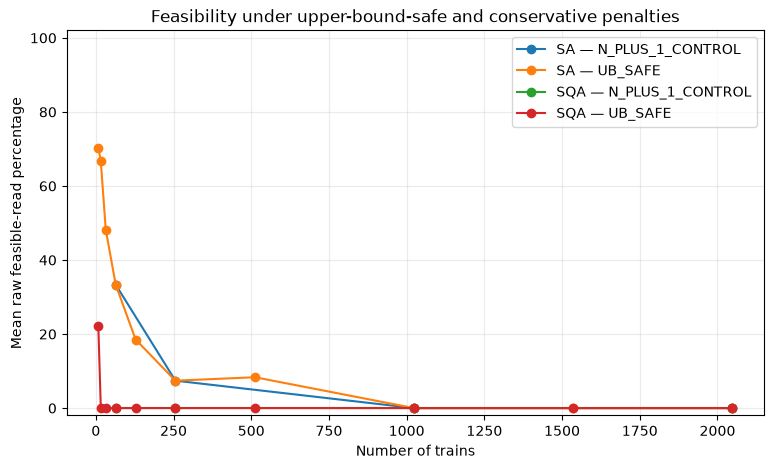

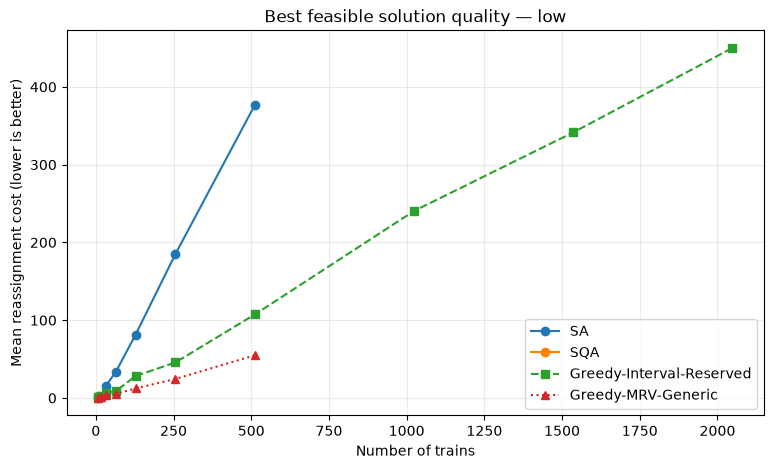

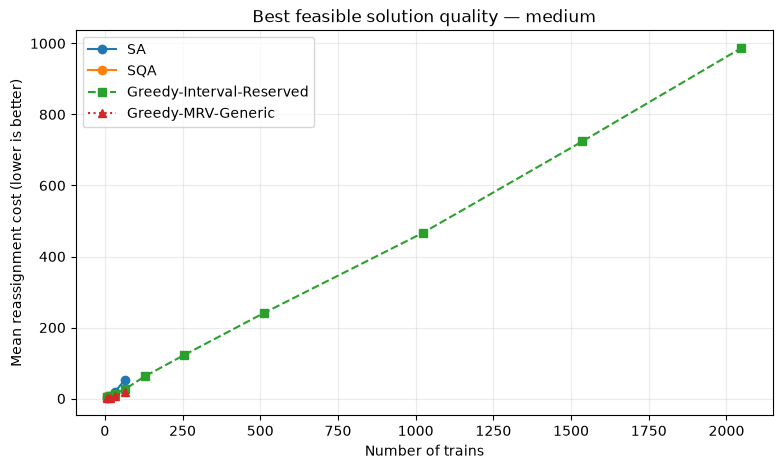

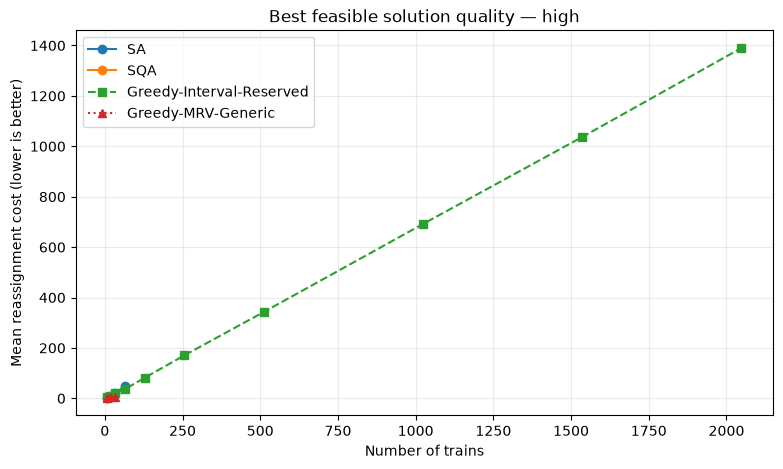

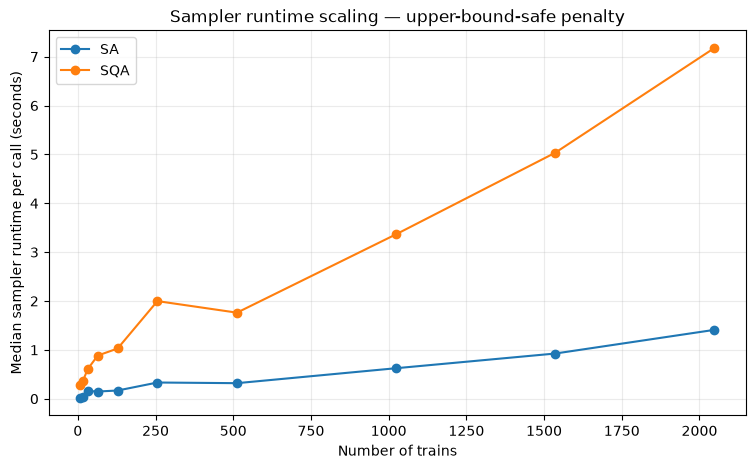

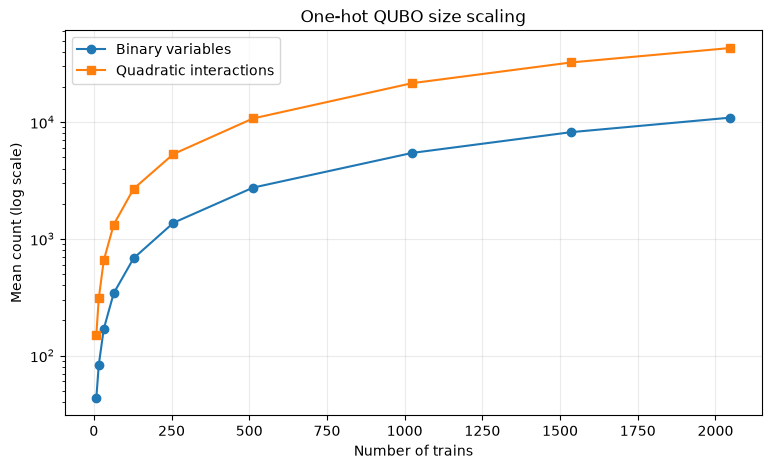

In [21]:
if not sampler_runs.empty:
    dataset_algorithm_summary = (sampler_runs.groupby(
        ["dataset_id", "n_trains", "difficulty", "algorithm", "penalty_regime"], dropna=False)
        .agg(repeats=("repeat", "nunique"), successful_runs=("run_status", lambda x: int((x == "OK").sum())),
             best_valid_cost=("best_valid_cost", "min"), mean_raw_feasibility_pct=("raw_feasibility_pct", "mean"),
             median_sampler_runtime_s=("runtime_s", "median"), median_end_to_end_s=("end_to_end_s", "median"))
        .reset_index().merge(dataset_diagnostics[[
            "dataset_id", "greedy_interval_cost", "greedy_mrv_cost", "best_greedy_cost",
            "exact_status", "exact_cost", "conflict_density", "adaptive_penalty_lambda",
            "conservative_penalty_lambda"
        ]], on="dataset_id", how="left"))
    dataset_algorithm_summary["gap_to_exact"] = np.where(
        dataset_algorithm_summary.exact_status == "OPTIMAL",
        dataset_algorithm_summary.best_valid_cost - dataset_algorithm_summary.exact_cost, np.nan)
    dataset_algorithm_summary["gap_to_best_greedy"] = (
        dataset_algorithm_summary.best_valid_cost - dataset_algorithm_summary.best_greedy_cost)

    scaling_summary = (dataset_algorithm_summary.groupby(
        ["n_trains", "difficulty", "algorithm", "penalty_regime"], dropna=False)
        .agg(datasets=("dataset_id", "nunique"),
             mean_best_valid_cost=("best_valid_cost", "mean"),
             median_best_valid_cost=("best_valid_cost", "median"),
             mean_feasibility_pct=("mean_raw_feasibility_pct", "mean"),
             median_sampler_runtime_s=("median_sampler_runtime_s", "median"),
             median_end_to_end_s=("median_end_to_end_s", "median"),
             mean_gap_to_exact=("gap_to_exact", "mean"),
             wins_over_best_greedy=("gap_to_best_greedy", lambda x: int((x < 0).sum())),
             valid_dataset_count=("best_valid_cost", lambda x: int(x.notna().sum())))
        .reset_index())

    paired_penalty_comparison = (dataset_algorithm_summary.pivot_table(
        index=["dataset_id", "n_trains", "difficulty", "algorithm"],
        columns="penalty_regime", values=["best_valid_cost", "mean_raw_feasibility_pct", "median_sampler_runtime_s"],
        aggfunc="first").reset_index())
    paired_penalty_comparison.columns = [
        "_".join([str(x) for x in col if str(x) not in ("", "None")]).rstrip("_")
        if isinstance(col, tuple) else str(col)
        for col in paired_penalty_comparison.columns
    ]

    greedy_comparison_summary = dataset_diagnostics[[
        "dataset_id", "n_trains", "difficulty", "seed", "greedy_interval_feasible",
        "greedy_interval_cost", "greedy_interval_runtime_s", "greedy_mrv_feasible",
        "greedy_mrv_cost", "greedy_mrv_runtime_s", "best_greedy_cost", "best_greedy_method",
        "witness_cost", "exact_status", "exact_cost"
    ]].copy()
    penalty_calibration = dataset_diagnostics[[
        "dataset_id", "n_trains", "difficulty", "seed", "greedy_interval_cost",
        "greedy_mrv_cost", "best_greedy_cost", "best_greedy_method", "penalty_source",
        "adaptive_penalty_lambda", "conservative_penalty_lambda", "penalty_bound_check"
    ]].copy()

    print("Scaling summary by size, difficulty, algorithm and penalty regime:")
    display(scaling_summary)
    print("Paired penalty comparison (only pre-registered control sizes have N_PLUS_1_CONTROL rows):")
    display(paired_penalty_comparison.head(20))
    print("Greedy baseline comparison:")
    display(greedy_comparison_summary.groupby("n_trains").agg(
        interval_mean_cost=("greedy_interval_cost", "mean"),
        mrv_mean_cost=("greedy_mrv_cost", "mean"),
        interval_feasible_rate=("greedy_interval_feasible", "mean"),
        mrv_feasible_rate=("greedy_mrv_feasible", "mean")).reset_index())
    print("Exact-search statuses:")
    display(dataset_diagnostics.groupby(["n_trains", "exact_status"]).size().rename("datasets").reset_index())

    # 1. Raw feasibility by size and penalty regime.
    fig, ax = plt.subplots(figsize=(9, 5))
    for (alg, regime), d in scaling_summary.groupby(["algorithm", "penalty_regime"]):
        z = d.groupby("n_trains").mean_feasibility_pct.mean().reset_index()
        ax.plot(z.n_trains, z.mean_feasibility_pct, marker="o", label=f"{alg} — {regime}")
    ax.set_xlabel("Number of trains")
    ax.set_ylabel("Mean raw feasible-read percentage")
    ax.set_title("Feasibility under upper-bound-safe and conservative penalties")
    ax.set_ylim(-2, 102); ax.grid(alpha=.25); ax.legend(); plt.show()

    # 2. Objective quality with both Greedy baselines.
    for difficulty in DIFFICULTIES:
        fig, ax = plt.subplots(figsize=(9, 5))
        sub = scaling_summary[(scaling_summary.difficulty == difficulty) & (scaling_summary.penalty_regime == "UB_SAFE")]
        for alg in ["SA", "SQA"]:
            d = sub[sub.algorithm == alg].sort_values("n_trains")
            ax.plot(d.n_trains, d.mean_best_valid_cost, marker="o", label=alg)
        gd = dataset_diagnostics[dataset_diagnostics.difficulty == difficulty].groupby("n_trains")[["greedy_interval_cost", "greedy_mrv_cost"]].mean()
        ax.plot(gd.index, gd.greedy_interval_cost, marker="s", linestyle="--", label="Greedy-Interval-Reserved")
        ax.plot(gd.index, gd.greedy_mrv_cost, marker="^", linestyle=":", label="Greedy-MRV-Generic")
        ax.set_xlabel("Number of trains"); ax.set_ylabel("Mean reassignment cost (lower is better)")
        ax.set_title(f"Best feasible solution quality — {difficulty}")
        ax.grid(alpha=.25); ax.legend(); plt.show()

    # 3. Runtime by solver.
    fig, ax = plt.subplots(figsize=(9, 5))
    runtime_data = sampler_runs[(sampler_runs.run_status == "OK") & (sampler_runs.penalty_regime == "UB_SAFE")]
    for alg in ["SA", "SQA"]:
        d = runtime_data[runtime_data.algorithm == alg].groupby("n_trains").runtime_s.median().reset_index()
        ax.plot(d.n_trains, d.runtime_s, marker="o", label=alg)
    ax.set_xlabel("Number of trains"); ax.set_ylabel("Median sampler runtime per call (seconds)")
    ax.set_title("Sampler runtime scaling — upper-bound-safe penalty")
    ax.grid(alpha=.25); ax.legend(); plt.show()

    # 4. QUBO size.
    fig, ax = plt.subplots(figsize=(9, 5))
    d = qubo_model_metrics[qubo_model_metrics.build_status == "BUILT"].groupby("n_trains").agg(
        variables=("n_variables", "mean"), interactions=("n_quadratic_interactions", "mean")).reset_index()
    ax.plot(d.n_trains, d.variables, marker="o", label="Binary variables")
    ax.plot(d.n_trains, d.interactions, marker="s", label="Quadratic interactions")
    ax.set_xlabel("Number of trains"); ax.set_ylabel("Mean count (log scale)")
    ax.set_yscale("log"); ax.set_title("One-hot QUBO size scaling")
    ax.grid(alpha=.25); ax.legend(); plt.show()
else:
    dataset_algorithm_summary = scaling_summary = paired_penalty_comparison = pd.DataFrame()
    greedy_comparison_summary = penalty_calibration = pd.DataFrame()
    print("No sampler output to summarize.")

## 10. Export results and experiment metadata

In [22]:
OUTPUT_DIR = Path.cwd() / "railway_v9_1_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def export_frame(frame, name):
    if frame is None or frame.empty:
        print("Not exported (empty):", name)
        return
    path = OUTPUT_DIR / name
    frame.to_csv(path, index=False)
    print("Saved:", path)

export_frame(dataset_diagnostics, "railway_v9_1_dataset_diagnostics.csv")
export_frame(generated_train_tables, "railway_v9_1_generated_train_tables.csv")
export_frame(conflict_edge_tables, "railway_v9_1_conflict_edges.csv")
export_frame(qubo_model_metrics, "railway_v9_1_qubo_model_metrics.csv")
export_frame(sampler_runs, "railway_v9_1_sampler_runs.csv")
export_frame(dataset_algorithm_summary, "railway_v9_1_dataset_algorithm_summary.csv")
export_frame(scaling_summary, "railway_v9_1_scaling_summary.csv")
export_frame(greedy_comparison_summary, "railway_v9_1_greedy_comparison.csv")
export_frame(penalty_calibration, "railway_v9_1_penalty_calibration.csv")
export_frame(paired_penalty_comparison, "railway_v9_1_paired_penalty_comparison.csv")

metadata = {
    "notebook_version": "v9_1_generalised_methodology_validation",
    "study_mode": STUDY_MODE,
    "python_version": sys.version.split()[0],
    "platform": platform.platform(),
    "cpu": platform.processor(),
    "ram_gb": RAM_GB,
    "openjij_version": OPENJIJ_VERSION,
    "n_platforms": N_PLATFORMS,
    "long_platform_count": LONG_PLATFORM_COUNT,
    "long_train_coach_threshold": LONG_TRAIN_COACH_THRESHOLD,
    "clearance_min_assumption": CLEARANCE_MIN,
    "train_counts": TRAIN_COUNTS,
    "seeds_by_size": SEEDS_BY_SIZE,
    "difficulty_levels": DIFFICULTIES,
    "difficulty_config": DIFFICULTY_CONFIG,
    "dataset_count": len(dataset_diagnostics) if not dataset_diagnostics.empty else 0,
    "encoding": "one_hot",
    "algorithms": ["SA", "SQA"],
    "greedy_baselines": ["Greedy_Interval_Reserved (V9 method)", "Greedy_MRV_Generic (no witness-pool reservation)"],
    "greedy_restarts_each": GREEDY_RESTARTS,
    "primary_penalty_rule": "best validated feasible Greedy cost + 1",
    "penalty_safety_argument": "Objective is non-negative; every invalid binary state has at least one penalty unit >= lambda; a feasible assignment of cost U exists and lambda=U+1>U, so every global QUBO minimizer is feasible.",
    "conservative_penalty_control": "N + 1",
    "run_conservative_penalty_control": RUN_CONSERVATIVE_PENALTY_CONTROL,
    "penalty_control_sizes": PENALTY_CONTROL_SIZES,
    "budget_by_size": BUDGET_BY_SIZE,
    "budget_tier_rule": "small <=64; medium 65-256; large >256",
    "exact_max_trains": EXACT_MAX_TRAINS,
    "exact_time_limit_s": EXACT_TIME_LIMIT_S,
    "max_qubo_variables": MAX_QUBO_VARIABLES,
    "max_qubo_interactions": MAX_QUBO_INTERACTIONS,
    "qubo_identity_all_built_passed": bool(qubo_model_metrics.loc[qubo_model_metrics.build_status == "BUILT", "identity_passed"].all()) if not qubo_model_metrics.empty else None,
    "sampler_success_rows": int((sampler_runs.run_status == "OK").sum()) if not sampler_runs.empty else 0,
    "sampler_error_rows": int((sampler_runs.run_status == "ERROR").sum()) if not sampler_runs.empty else 0,
    "resource_skipped_datasets": int((~dataset_diagnostics.resource_gate_passed).sum()) if not dataset_diagnostics.empty else 0,
    "sampler_logging": "Explicit sample_qubo kwargs, dedicated seed, full response.info JSON, response.info.schedule when available, and before/after process RSS snapshots are saved per sampler run. beta_range/beta_schedule_type are not explicitly overridden.",
    "synthetic_data_notice": "All train-level schedules, delays, nominal platform assignments, coach counts and conflicts are synthetic; no station-specific dataset is used.",
    "quantum_notice": "OpenJij SQA is a classical simulation, not quantum hardware.",
    "raw_feasibility_notice": "No repair decoder is applied; only internally valid conflict-free raw sampler samples count as feasible.",
    "interpretation_notice": "Timeouts and resource skips are not infeasibility proofs or solver failures. Exact optimality gaps are reported only for proven OPTIMAL exact searches. Adaptive penalty guarantees valid ground states, not valid finite-budget sampler outputs.",
    "scenario_notice": "Difficulty changes per-platform target utilisation and nominal/witness agreement probability. Observed conflict density, mean degree and maximum concurrency are exported for audit.",
    "planned_main_sampler_calls": EXPECTED_MAIN_CALLS,
    "planned_control_sampler_calls": EXPECTED_CONTROL_CALLS,
    "actual_sampler_rows": len(sampler_runs),
}
with open(OUTPUT_DIR / "railway_v9_1_experiment_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)
print("V9.1 outputs saved to:", OUTPUT_DIR.resolve())

Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v9_1_outputs\railway_v9_1_dataset_diagnostics.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v9_1_outputs\railway_v9_1_generated_train_tables.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v9_1_outputs\railway_v9_1_conflict_edges.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v9_1_outputs\railway_v9_1_qubo_model_metrics.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v9_1_outputs\railway_v9_1_sampler_runs.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v9_1_outputs\railway_v9_1_dataset_algorithm_summary.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v9_1_outputs\railway_v9_1_scaling_summary.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v9_1_outputs\railway_v9_1_greedy_comparison.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v9_1_outputs\railway_v9_1_penalty_calibration.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v9_1_outputs\railway

## 11. Mandatory review checklist before treating V9.1 results as evidence

- [ ] Pilot QUBO identity checks pass using the adaptive penalty.
- [ ] Exhaustive tiny-instance test confirms the adaptive penalty has only valid global ground states.
- [ ] Every adaptive penalty is strictly greater than its recorded validated feasible upper bound.
- [ ] Both Greedy baselines are described separately; Greedy-MRV does not use witness-pool reservation.
- [ ] The paired `N_PLUS_1_CONTROL` uses the same dataset, algorithm, run seed, reads, sweeps and repeat index as `UB_SAFE` on control sizes.
- [ ] The primary and control penalty regimes are not pooled without labeling.
- [ ] Every sampler row includes sampler class, explicit `sample_qubo` kwargs, dedicated sampler seed, response.info, response.info schedule when available, normalization factor, reads, sweeps and RSS snapshots.
- [ ] Raw sampler feasibility is separated from objective quality; no repaired samples are counted.
- [ ] Exact `OPTIMAL` is the only status used to calculate an optimality gap.
- [ ] `TIMEOUT`, `NOT_RUN_SIZE_LIMIT`, and `SKIPPED_RESOURCE_LIMIT` remain distinct.
- [ ] Observed conflict density is checked for each size and difficulty; labels are not treated as ground-truth hardness.
- [ ] The pilot is reviewed before switching to `FULL`.
- [ ] All CSVs, metadata, and executed notebook are retained together.

**Interpretation guardrails:** V9.1 can test whether the upper-bound-safe penalty improves finite-budget feasibility relative to `N+1`; it cannot guarantee that annealing samples are valid. SQA is a classical simulation. No quantum advantage claim is supported by this experiment.